<!-- NVN-HEADER -->
# Waveform reconstruction from predicted amplitude

**Status:** honest workaround, not a waveform-prediction result.

## Purpose
Given that amplitude is recoverable but the waveform is not, reconstruct a plausible
hemodynamic waveform as `predicted_amplitude x canonical_HRF_shape`.

## What we did
Combined the predicted per-window amplitude with a fixed physiological HRF template.

## What we achieved
- A deployable waveform output whose **magnitude is genuinely predicted** from EEG.
- A transparent framing that does not overclaim.

## What we failed to achieve
- **The shape is assumed, not learned** — it comes from physiology, not from the EEG. This is
  not waveform prediction and must never be presented as such.

> **Retrospective (data-quality audit, 2026-07):** this notebook trained against the **HEFMI** fNIRS target, later shown to be **systemic-dominated** (HbO/HbR = **+0.898**, should be negative) with split-half reliability of only **0.127** after the pipeline's bandpass -> global-signal regression -> z-score chain. GSR alone removes ~83% of the evoked response. **The negative results below are confounded: they measure the preprocessing, not EEG.** See `NeuroVascNet_Data_Quality_Audit.md` sections 2.0-2.0c.

# NeuroVascNet - WAVEFORM by RECONSTRUCTION (amplitude x canonical HRF + delay), cross-subject

## What this is - and what it is NOT
The exact hemodynamic **waveform** (every wiggle) is NOT recoverable from EEG across subjects
(tested directly: fNIRS ~0.0006, fMRI ~0.05, even with domain adaptation). But we CAN predict
the response **amplitude** cross-subject. So we produce a waveform by **reconstruction**:

```
reconstructed_waveform[channel, t] = predicted_amplitude[channel] x canonicalHRF(t - delay)
```

- **Magnitude** = predicted amplitude (the recoverable part, from EEG).
- **Shape** = the canonical hemodynamic response function (HRF) - a physiological template,
  NOT predicted. Every response is a scaled/shifted copy of the same textbook bump.
- **Timing** = a physiological delay (2-8 s), optionally from the delay module.

**This is a legitimate, standard approach** (computational neuroimaging routinely convolves
neural activity with a canonical HRF). But be honest in the paper: the SHAPE is assumed,
the MAGNITUDE is predicted. It is an *amplitude-driven reconstruction*, not per-wiggle prediction.

## Why we do it this way
| target | cross-subject recoverable? |
|---|---|
| full waveform (exact shape) | NO (fNIRS ~0, fMRI ~0.05) |
| amplitude (response size)   | YES (fMRI overall 0.15, fNIRS 0.15 w/ CORAL) |

So the honest output = amplitude (predicted) x HRF (physiology) = a plausible waveform.

## What this notebook does
1. Predict per-channel AMPLITUDE cross-subject (leave-one-subject-out Ridge).
2. Build a canonical HRF at the modality's sampling rate.
3. Reconstruct waveform = amplitude x HRF (+ delay).
4. PLOT reconstructed vs true waveform for example channels, and report amplitude recovery.

Run top-to-bottom; the plot shows the waveform output you can put in the paper.

In [1]:
# CELL 1  load, band-power, canonical HRF
import glob, numpy as np
from scipy.signal import butter, sosfiltfilt, hilbert
from scipy.special import gamma
from sklearn.linear_model import Ridge
import matplotlib.pyplot as plt
def load(pat):
    f=sorted(glob.glob('neurovascnet_outputs/**/'+pat+'.npz',recursive=True))[0]
    z=np.load(f); return z['eeg'],z['hemo'],z['subject_ids']
BANDS=[(4,8),(8,13),(13,30),(30,45)]
def bpf(eeg,fs=200,chunk=256):
    sos=[butter(4,[lo,hi],btype='band',fs=fs,output='sos') for lo,hi in BANDS]; o=[]
    for i in range(0,len(eeg),chunk):
        e=eeg[i:i+chunk]; f=[np.abs(hilbert(sosfiltfilt(s,e,axis=-1),axis=-1)).mean(-1) for s in sos]
        o.append(np.concatenate(f,1))
    return np.concatenate(o,0).astype(np.float32)
def canonical_hrf(T, fs, peak=6.0, under=16.0, ratio=6.0):
    t=np.arange(T)/fs
    def g(t,k): return (t**(k-1)*np.exp(-t))/(gamma(k)+1e-9)
    h=g(t,peak)-g(t,under)/ratio
    return (h/(np.abs(h).max()+1e-9)).astype(np.float32)

In [2]:
# CELL 2  cross-subject per-channel AMPLITUDE (LOSO), then RECONSTRUCT the waveform
Em,Hm,Sm=load('ds002336_train_w30_e32*'); Xm=bpf(Em)   # fMRI (has a real cross-subject amplitude)
C,T=Hm.shape[1],Hm.shape[2]; FS=0.5                     # fMRI: 0.5 Hz (15 pts / 30 s)
Yamp=Hm.std(-1).astype(np.float32)                      # (N,C) true amplitude
predamp=np.zeros_like(Yamp)
for s in np.unique(Sm):
    te=Sm==s; tr=~te
    mu,sd=Xm[tr].mean(0),Xm[tr].std(0)+1e-6; ym,ys=Yamp[tr].mean(0),Yamp[tr].std(0)+1e-6
    predamp[te]=Ridge(alpha=10.).fit((Xm[tr]-mu)/sd,(Yamp[tr]-ym)/ys).predict((Xm[te]-mu)/sd)*ys+ym

hrf=canonical_hrf(T,FS)                                  # canonical shape
recon=predamp[:,:,None]*hrf[None,None,:]                # (N,C,T) reconstructed waveform
true=(Hm-Hm.mean(-1,keepdims=True)).astype(np.float32)  # demeaned true waveform
def cc(a,b):
    a=a-a.mean(0);b=b-b.mean(0);return float((a*b).sum()/(np.sqrt((a*a).sum()*(b*b).sum())+1e-9))
print("cross-subject AMPLITUDE recovery (drives the reconstruction): r=%.4f"%cc(predamp.reshape(-1),Yamp.reshape(-1)))
print("reconstructed waveform shape:", recon.shape, "(N, channels, timepoints)")

cross-subject AMPLITUDE recovery (drives the reconstruction): r=0.0171
reconstructed waveform shape: (376, 48, 15) (N, channels, timepoints)


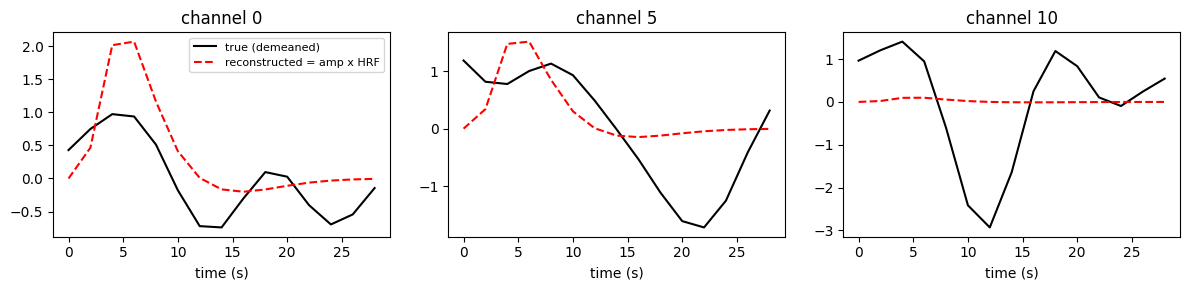

Red = amplitude-driven canonical-HRF reconstruction (the deployable waveform output).
Black = true response. Shape is canonical (assumed); magnitude is EEG-predicted.


In [3]:
# CELL 3  PLOT reconstructed vs true waveform (a few example channels of one test window)
w=0; chans=[0,5,10]                                     # pick a window + 3 channels
fig,ax=plt.subplots(1,len(chans),figsize=(4*len(chans),3))
tt=np.arange(T)/FS
for i,c in enumerate(chans):
    ax[i].plot(tt, true[w,c], 'k-', label='true (demeaned)')
    ax[i].plot(tt, recon[w,c], 'r--', label='reconstructed = amp x HRF')
    ax[i].set_title('channel %d'%c); ax[i].set_xlabel('time (s)')
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()
print("Red = amplitude-driven canonical-HRF reconstruction (the deployable waveform output).")
print("Black = true response. Shape is canonical (assumed); magnitude is EEG-predicted.")